In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score, KFold
from matplotlib import cm
from matplotlib.colors import Normalize
from scipy.ndimage import gaussian_filter1d


In [27]:
file_path = "Data_MN_Model/Data_final/Controller/spike_array_exc.jld2"
# spikes_exc_newInput
with h5py.File(file_path, 'r') as f:
    spike_array = f['spike_array'][:]  # (600000, 87)

In [14]:

# Assuming you already have the spike_array loaded
# Define the window size (e.g., 50 ms at 20 kHz sampling rate)
window_size_ms = 300 # 50 ms window
sampling_rate = 20000  # 20 kHz
window_size_samples = int((window_size_ms / 1000) * sampling_rate)  # Convert window size to samples

# Step 1: Initialize the array to store the firing rates
smoothed_spike_array = np.zeros((spike_array.shape[0] // window_size_samples, spike_array.shape[1]))

# Step 2: For each neuron, sum the spikes within each window and convert to rate
for neuron in range(spike_array.shape[1]):
    for i in range(0, spike_array.shape[0] - window_size_samples, window_size_samples):
        smoothed_spike_array[i // window_size_samples, neuron] = np.sum(spike_array[i:i + window_size_samples, neuron]) / (window_size_ms / 1000)  # Convert to Hz

# rate_array now contains the firing rates in Hz for each neuron over time


In [28]:
import numpy as np

# Define the window size (300 ms at 20 kHz sampling rate)
window_size_ms = 300  # 300 ms window
sampling_rate = 20000  # 20 kHz
window_size_samples = int((window_size_ms / 1000) * sampling_rate)  # Convert window size to samples

# Step 1: Initialize the array to store the smoothed firing rates
smoothed_spike_array = np.zeros_like(spike_array)

# Step 2: Apply moving average over each neuron's spike train
for neuron in range(spike_array.shape[1]):
    smoothed_spike_array[:, neuron] = np.convolve(spike_array[:, neuron], np.ones(window_size_samples)/window_size_samples, mode='same')

# Convert from spike counts to firing rates (Hz)
# smoothed_spike_array = smoothed_spike_array * sampling_rate


In [29]:
smoothed_spike_array.shape

(600000, 87)

Explained variance by each component: [0.78673697 0.08560358 0.04549569 0.01938616 0.01151847]
Cumulative explained variance: [0.78673697 0.87234055 0.91783624 0.93722239 0.94874086]


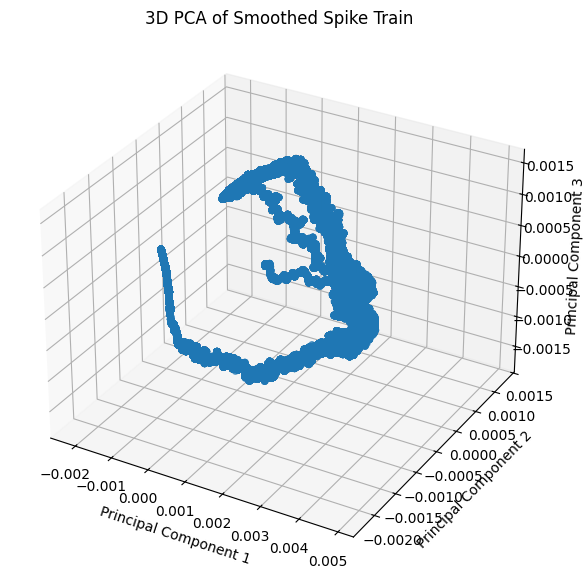

In [24]:

from sklearn.decomposition import PCA


# Step 3: Perform PCA on the smoothed spike array
pca = PCA(n_components=5)  # Keep 3 components for 3D visualization
principal_components = pca.fit_transform(smoothed_spike_array)

# Step 4: Output explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_explained_variance = np.cumsum(explained_variance)
print(f"Explained variance by each component: {explained_variance}")
print(f"Cumulative explained variance: {cumulative_explained_variance}")

# Step 5: Plot the first three principal components in 3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Plotting the three principal components
ax.scatter(principal_components[:, 0], principal_components[:, 1], principal_components[:, 2], alpha=0.7)

# Label the plot
ax.set_title('3D PCA of Smoothed Spike Train')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')

plt.show()


Explained variance by each component: [0.85726637 0.05253648 0.03559243 0.01288613 0.00597554]
Cumulative explained variance: [0.85726637 0.90980286 0.94539528 0.95828141 0.96425696]


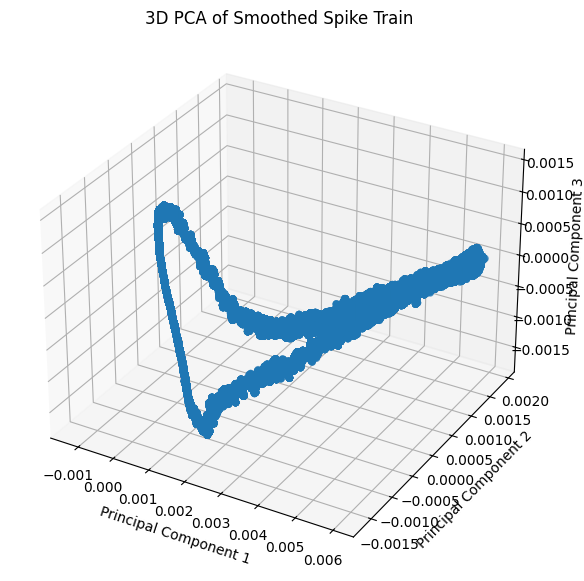

In [30]:

from sklearn.decomposition import PCA


# Step 3: Perform PCA on the smoothed spike array
pca = PCA(n_components=5)  # Keep 3 components for 3D visualization
principal_components = pca.fit_transform(smoothed_spike_array)

# Step 4: Output explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_explained_variance = np.cumsum(explained_variance)
print(f"Explained variance by each component: {explained_variance}")
print(f"Cumulative explained variance: {cumulative_explained_variance}")

# Step 5: Plot the first three principal components in 3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Plotting the three principal components
ax.scatter(principal_components[:, 0], principal_components[:, 1], principal_components[:, 2], alpha=0.7)

# Label the plot
ax.set_title('3D PCA of Smoothed Spike Train')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')

plt.show()
